# Homework 8: Time-Series Forecasting with LSTM Networks

**Due:** Midnight on Sunday, October 25, 2026 (with a 2-hour + 1-minute grace period)

## Overview

In this homework, you will use **Long Short-Term Memory (LSTM) networks** to predict hourly electricity demand. Unlike the text classification problems we have studied, electricity demand is a *time series*: the order of observations matters, and patterns may extend across hours, days, or weeks.

We will use electricity demand data from the New York Independent System Operator (NYISO), beginning with a working LSTM model that predicts the next hour's demand from the preceding seven days of observations.

You will investigate how the model's forecasting performance depends on the amount of historical information provided, the number of future hours predicted, and the architecture of the neural network. Finally, you will compare two fundamentally different approaches to multi-step forecasting.

## Direct and Autoregressive Forecasting

We will investigate two approaches to predicting future values:

- **Direct forecasting:** The model predicts one or more future values in a single forward pass. For example, an LSTM can take the preceding 168 hours of demand and produce predictions for the next 24 hours simultaneously.
- **Autoregressive forecasting:** The model predicts one hour ahead, adds that prediction to its input sequence, and repeats the process to predict subsequent hours. Because later predictions depend on earlier predictions, errors may accumulate as the forecast horizon increases.

Both approaches use historical observations, but they differ in how they generate predictions over multiple future time steps.


![Screenshot 2026-10-16 at 9.18.41 AM.png](attachment:046ac74d-28b1-4889-ad5d-101aeda2aa1d.png)

## What You'll Do

**Problem 1 — Exploring Lookback and Horizon**

Investigate how changing the length of the input sequence (*lookback*) and the number of future observations predicted (*horizon*) affects forecasting performance. You will train models with different configurations and compare their validation errors.

**Problem 2 — Exploring LSTM Architectures**

Investigate three architectural modifications: adding Dense layers, stacking LSTM layers, and using a bidirectional LSTM. You will compare these architectures using the same forecasting task and training procedure.

**Problem 3 — Direct vs. Autoregressive Forecasting**

Implement a recursive forecasting procedure that uses a one-hour-ahead LSTM to predict 24 hours into the future. You will compare its predictions with a direct 24-hour forecasting model and examine how prediction error changes with forecast horizon.

**Problem 4 — Final Evaluation on the Test Set**

Select the better 24-hour forecasting approach using validation performance, then evaluate it on held-out test data and report MAE in scaled units and megawatts.

## Training and Evaluation

Throughout the homework, we will follow a consistent procedure:

- Train neural networks using **Mean Squared Error (MSE)** as the loss function.
- Use early stopping to select the epoch with the lowest validation loss.
- Report **Mean Absolute Error (MAE)** at the selected epoch.
- Compare models using validation data, keeping the test set separate from model development.

Unless otherwise specified, reported validation MAE values are in **scaled units**.

The goal is not simply to achieve the lowest prediction error, but to understand how the design of a recurrent neural network and its forecasting strategy influence its ability to predict sequential data.

## Setup and Data Loading


In [1]:
# Standard library
import os
import time

# Environment settings (before importing TensorFlow)
os.environ["PYTHONHASHSEED"] = "42"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# Data and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, LSTM, GRU, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
random_seed = 42
tf.keras.utils.set_random_seed(random_seed)

# Convenience
def format_hms(seconds):
    """Format elapsed seconds as H:MM:SS."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


### Learning Curves and Experiment Results

We will use **MSE as the training loss**, and track **MAE** during training.

The epoch with the lowest validation MSE (`val_loss`) will be selected as the best epoch. We report the MAE **at that same epoch**, rather than independently selecting the lowest value of each metric.

All learning-curve metrics are expressed in **scaled units**.

The function `plot_learning_curves_scaled()` plots the learning curves and stores the results of each experiment. Call `print_results()` to compare the experiments performed so far.


In [2]:
# Global experiment registry
results = {}

def plot_learning_curves_scaled(history, title="Learning Curves", verbose=True, plot=True):
    """Plot MAE in scaled units and record metrics at minimum validation MSE."""
    H = history.history if hasattr(history, "history") else history

    required = ("loss", "val_loss", "mae", "val_mae")
    missing = [key for key in required if key not in H]
    if missing:
        raise ValueError(f"Missing history metrics: {missing}")

    val_loss = np.asarray(H["val_loss"])
    mae = np.asarray(H["mae"])
    val_mae = np.asarray(H["val_mae"])
    epochs = np.arange(1, len(mae) + 1)

    # Select epoch by minimum validation MSE (not minimum MAE)
    best_idx = int(np.argmin(val_loss))
    best_epoch = best_idx + 1

    # Record MAE at the selected epoch
    summary = {
        "selected_epoch": best_epoch,
        "val_mae_at_min_valloss": float(val_mae[best_idx]),
        "train_mae_at_sel": float(mae[best_idx]),
        "val_loss": float(val_loss[best_idx]),
        "units": "scaled"
    }
    results[title] = summary

    # Plot training and validation MAE
    if plot:
        fig, ax = plt.subplots(figsize=(9, 5))

        ax.plot(epochs, mae, label="Training MAE")
        ax.plot(epochs, val_mae, label="Validation MAE")

        ax.axvline(
            best_epoch,
            color="gray",
            linestyle=":",
            label=f"Selected epoch = {best_epoch} (min val_loss)"
        )

        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MAE (scaled units)")
        ax.grid(True, linestyle=":", alpha=0.5)
        ax.legend()

        plt.tight_layout()
        plt.show()

    if verbose:
        print(f"Selected epoch: {best_epoch} (minimum validation MSE)")
        print(f"Training MAE:   {summary['train_mae_at_sel']:.4f}")
        print(f"Validation MAE: {summary['val_mae_at_min_valloss']:.4f}")

    return summary


def print_results(sort_by="val_mae_at_min_valloss"):
    """Display experiments ranked by validation MAE at the selected epoch."""

    if not results:
        print("No results recorded yet.")
        return

    print(f"{'Experiment':<35} {'Val MAE':>12} {'Epoch':>8}")
    print("-" * 58)

    for name, info in sorted(
        results.items(),
        key=lambda item: item[1][sort_by]
    ):
        print(
            f"{name:<35} "
            f"{info['val_mae_at_min_valloss']:>12.4f} "
            f"{info['selected_epoch']:>8}"
        )

    print("\nMAE is in scaled units; epoch selected by minimum validation MSE.")

### Training and Validation

The function `train_and_validate()` provides a common training procedure for all experiments. It:

- Trains using MSE loss, tracking MAE.
- Uses Adam with a learning rate of 0.001 by default.
- Uses early stopping based on validation MSE, restoring the best model weights.
- Plots learning curves and records the experiment in `results`.

The function uses the global `X_train`, `y_train`, `X_val`, and `y_val` unless datasets are supplied explicitly.

```python
# Use the current datasets
train_and_validate(model, title="Experiment 1")

# Supply different datasets
train_and_validate(model, X_train=new_X_train, y_train=new_y_train,
                   X_val=new_X_val, y_val=new_y_val, title="Experiment 2")
```

**Important:** We use validation performance to compare models and select hyperparameters. The held-out test set is reserved for final evaluation.


In [3]:
def train_and_validate(
    model,
    X_train=None, y_train=None,
    X_val=None, y_val=None,
    *,
    epochs=50,
    batch_size=64,
    optimizer="Adam",
    lr_schedule=1e-3,
    clipnorm=1.0,
    patience=5,
    callbacks=None,
    title="LSTM Experiment",
    verbose=0,
    plot_scaled_curves=True,
    return_history=False
):
    """Train and validate regression model; return summary or (history, summary)."""
    g = globals()
    X_train = X_train if X_train is not None else g.get("X_train")
    y_train = y_train if y_train is not None else g.get("y_train")
    X_val = X_val if X_val is not None else g.get("X_val")
    y_val = y_val if y_val is not None else g.get("y_val")

    if any(x is None for x in (X_train, y_train, X_val, y_val)):
        raise ValueError("Training and validation datasets are required.")

    if isinstance(optimizer, str):
        opt = getattr(keras.optimizers, optimizer)(
            learning_rate=lr_schedule, clipnorm=clipnorm
        )
    else:
        opt = optimizer

    model.compile(
        optimizer=opt,
        loss="mse",
        metrics=[
            keras.metrics.MeanAbsoluteError(name="mae")
        ]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=patience,
        min_delta=0.0,
        restore_best_weights=True
    )
    cb = [early_stop] + ([] if callbacks is None else list(callbacks))

    print(f"\n{title}\n")
    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=cb,
        shuffle=True,
        verbose=verbose
    )
    elapsed = time.time() - start

    summary = plot_learning_curves_scaled(
        history, title=title, plot=plot_scaled_curves
    )
    summary["elapsed_sec"] = elapsed
    print(f"Training time: {format_hms(elapsed)}")

    if return_history:
        return history, summary
    return summary


### Load and Prepare the Data

We will use hourly electricity demand data from the New York Independent System Operator (NYISO).

The original dataset contains one row per day, with separate columns for hourly measurements. We will convert it into a continuous hourly time series.

For this homework:

- Use the first **five months** of data.
- Divide the observations chronologically into 70% training, 15% validation, and 15% testing.
- Fit the `StandardScaler` using training data only.
- Preserve the chronological order of the validation and test observations.

Electricity demand is measured in **megawatts (MW)**.


Data period: 2025-01-01 00:00:00 to 2025-05-31 23:00:00
Total hours: 3624
Training:    2536
Validation:  543
Testing:     545


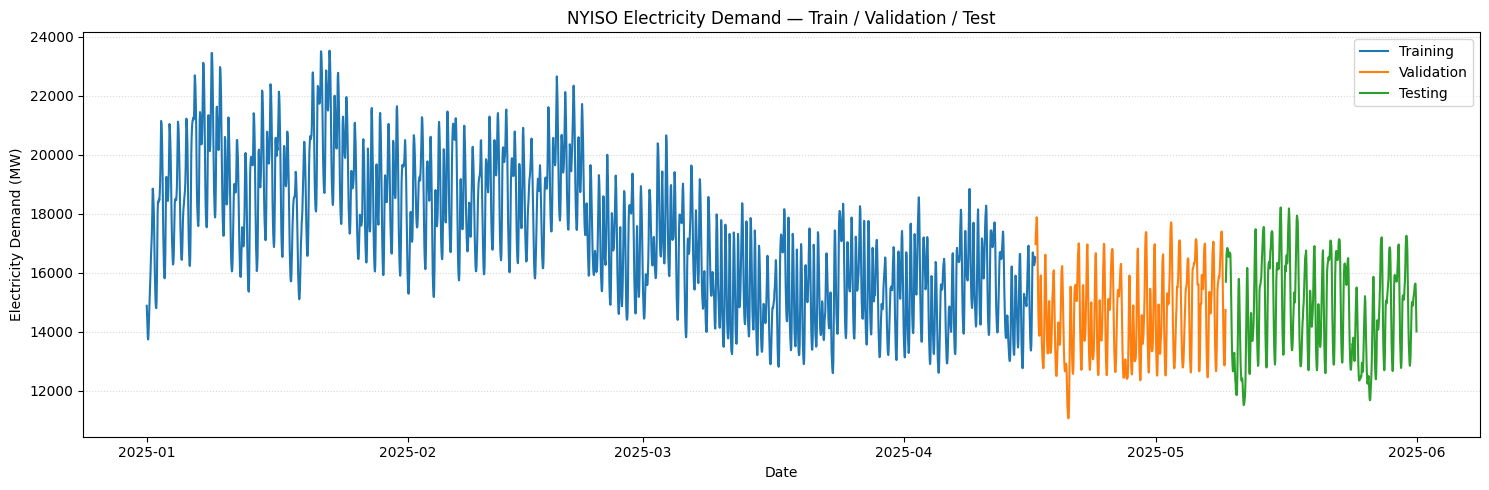

In [4]:
# Load NYISO hourly electricity demand
url = "https://www.cs.bu.edu/fac/snyder/cs505/Data/nyiso_loads.csv"
df = pd.read_csv(url)

# Columns Hr1 through Hr24
hour_cols = [f"Hr{i}" for i in range(1, 25)]
if not set(hour_cols).issubset(df.columns):
    raise ValueError("Expected hourly columns Hr1 through Hr24.")

# Convert wide format to one row per hour
long_df = df.melt(
    id_vars=["Year", "Month", "Day"],
    value_vars=hour_cols,
    var_name="Hour",
    value_name="Load"
)

# Construct hourly timestamps
hour_number = long_df["Hour"].str[2:].astype(int)
long_df["Datetime"] = (
    pd.to_datetime(long_df[["Year", "Month", "Day"]])
    + pd.to_timedelta(hour_number - 1, unit="h")
)
long_df = long_df.sort_values("Datetime")

load_series = pd.Series(
    pd.to_numeric(long_df["Load"], errors="coerce").to_numpy(),
    index=long_df["Datetime"],
    name="NYISO_Load"
)

# Keep the first five calendar months
start = load_series.index.min().normalize()
end = start + pd.DateOffset(months=5)
s5 = load_series.loc[
    (load_series.index >= start) & (load_series.index < end)
].copy()

# Enforce hourly frequency and fill short gaps
s5 = s5.asfreq("h")
s5 = s5.interpolate(method="time", limit=3)
if s5.isna().any():
    raise ValueError("Missing observations remain after interpolation. Inspect the data before continuing.")

# Chronological 70/15/15 split
N = len(s5)
n_train = int(0.70 * N)
n_val = int(0.15 * N)
n_test = N - n_train - n_val

train = s5.iloc[:n_train]
val = s5.iloc[n_train:n_train + n_val]
test = s5.iloc[n_train + n_val:]

print(f"Data period: {s5.index[0]} to {s5.index[-1]}")
print(f"Total hours: {N}")
print(f"Training:    {len(train)}")
print(f"Validation:  {len(val)}")
print(f"Testing:     {len(test)}")

# Plot chronological split
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(train.index, train.values, label="Training")
ax.plot(val.index, val.values, label="Validation")
ax.plot(test.index, test.values, label="Testing")
ax.set_title("NYISO Electricity Demand — Train / Validation / Test")
ax.set_xlabel("Date")
ax.set_ylabel("Electricity Demand (MW)")
ax.grid(True, axis="y", linestyle=":", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()


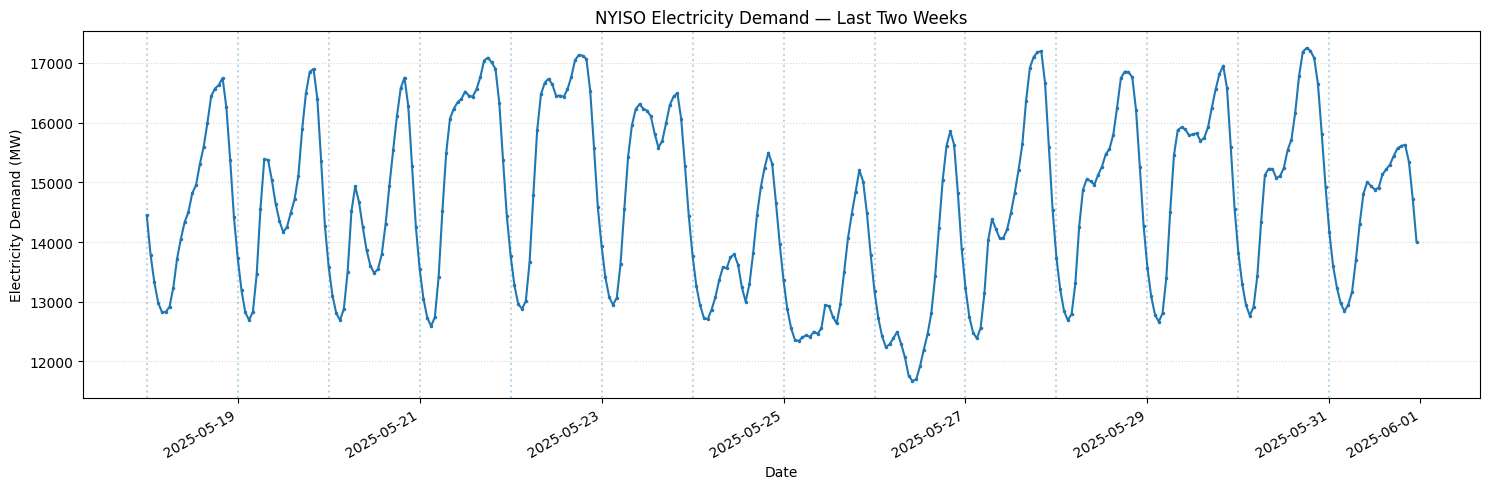

In [5]:
# Examine daily and weekly demand patterns
last_two_weeks = s5.tail(24 * 14)
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(last_two_weeks.index, last_two_weeks.values, marker=".", markersize=3)

# Mark midnight at the start of each day
for day in pd.date_range(
    last_two_weeks.index[0].normalize(),
    last_two_weeks.index[-1].normalize(),
    freq="D"
):
    ax.axvline(day, linestyle=":", alpha=0.3)

ax.set_title("NYISO Electricity Demand — Last Two Weeks")
ax.set_xlabel("Date")
ax.set_ylabel("Electricity Demand (MW)")
ax.grid(True, axis="y", linestyle=":", alpha=0.5)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


### Preprocess Data into Sliding Windows

Our prediction task is to predict the next `horizon` hours of electricity demand from the preceding `lookback` hours.

For the baseline:

- `lookback = 168`: use the preceding seven days of hourly observations.
- `horizon = 1`: predict demand for the next hour.

The input to the LSTM has shape `(samples, lookback, 1)`, where the final dimension represents the single input feature.

The target has shape `(samples, horizon)`.

**Important details:**

- The scaler is fitted only to training data.
- Validation windows may use earlier training observations as historical context.
- Test windows may use earlier training and validation observations as historical context.
- All prediction targets remain entirely within their respective training, validation, or test partitions.

Using past observations from a preceding partition is not data leakage.

This is **direct forecasting**, not autoregressive forecasting. For `horizon > 1`, the network produces several future predictions simultaneously without feeding its predictions back as inputs.


In [6]:
# Scale using training data only
scaler = StandardScaler()
train_x = scaler.fit_transform(train.to_numpy().reshape(-1, 1)).astype(np.float32)
val_x = scaler.transform(val.to_numpy().reshape(-1, 1)).astype(np.float32)
test_x = scaler.transform(test.to_numpy().reshape(-1, 1)).astype(np.float32)


def make_windows(arr, lookback, horizon):
    """Return X (samples, lookback, 1), y (samples, horizon)."""
    if lookback < 1 or horizon < 1:
        raise ValueError("lookback and horizon must be positive.")
    if len(arr) < lookback + horizon:
        raise ValueError("Not enough observations for these windows.")

    X, y = [], []
    for i in range(lookback, len(arr) - horizon + 1):
        X.append(arr[i-lookback:i, 0])
        y.append(arr[i:i+horizon, 0])
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)
    return X[..., None], y


def build_datasets(lookback=168, horizon=1):
    """Create chronological train/validation/test windows with past-only context."""
    X_tr, y_tr = make_windows(train_x, lookback, horizon)

    val_context = np.concatenate([train_x[-lookback:], val_x], axis=0)
    X_va, y_va = make_windows(val_context, lookback, horizon)

    previous = np.concatenate([train_x, val_x], axis=0)
    test_context = np.concatenate([previous[-lookback:], test_x], axis=0)
    X_te, y_te = make_windows(test_context, lookback, horizon)
    return X_tr, y_tr, X_va, y_va, X_te, y_te

# Baseline configuration
lookback = 24 * 7
horizon = 1
X_train, y_train, X_val, y_val, X_test, y_test = build_datasets(lookback, horizon)

print("Dataset shapes:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test:", y_test.shape)


Dataset shapes:
X_train: (2368, 168, 1) y_train: (2368, 1)
X_val:   (543, 168, 1) y_val:   (543, 1)
X_test:  (545, 168, 1) y_test: (545, 1)


### Baseline LSTM Model

We begin with a simple LSTM model:

- One LSTM layer with 32 units.
- Dropout of 0.2.
- A Dense hidden layer with 16 ReLU units.
- A linear output layer with `horizon` units.

The output is linear because we are predicting numerical electricity demand, not class probabilities.

We train using MSE loss, with early stopping based on validation loss.

This baseline gives us a reference against which to compare the experiments in Problems 1 and 2.



Baseline LSTM



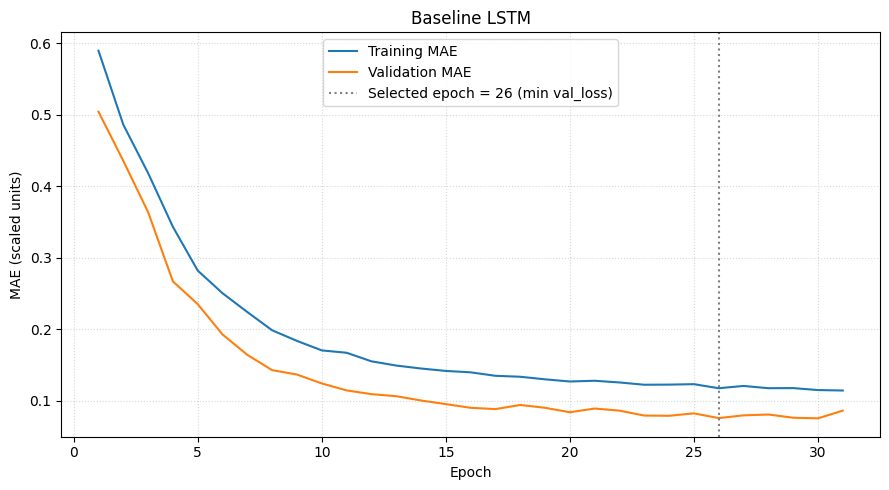

Selected epoch: 26 (minimum validation MSE)
Training MAE:   0.1176
Validation MAE: 0.0759
Training time: 00:00:18


In [7]:
def make_baseline_model(lookback, horizon):
    """Construct the baseline LSTM architecture."""
    return Sequential([
        Input(shape=(lookback, 1)),
        LSTM(32),
        Dropout(0.2),
        Dense(16, activation="relu",
              kernel_initializer=keras.initializers.HeNormal(seed=random_seed)),
        Dense(horizon)
    ])

# Establish reproducible baseline initialization
tf.keras.utils.set_random_seed(random_seed)
baseline_model = make_baseline_model(lookback, horizon)

# Preserve baseline configuration and datasets
baseline_lookback = lookback
baseline_horizon = horizon
baseline_X_val, baseline_y_val = X_val, y_val
baseline_X_test, baseline_y_test = X_test, y_test

baseline_history, baseline_info = train_and_validate(
    baseline_model, title="Baseline LSTM", verbose=0, return_history=True
)


### Visualizing Predictions

Let's examine how well the baseline model predicts electricity demand.

We will plot actual and predicted demand for the **last seven days of the validation period**.

We use the validation set because we will compare and modify models in the following problems. The test set is reserved for final evaluation.

For multi-step forecasts (`horizon > 1`), different prediction windows may forecast the same hour. To produce a single continuous predicted time series for visualization, we average the overlapping forecasts.

We also report MAE for the individual forecast steps. These metrics are computed from the original predictions, before averaging overlapping forecasts.


Baseline Validation MAE: 176.16 MW


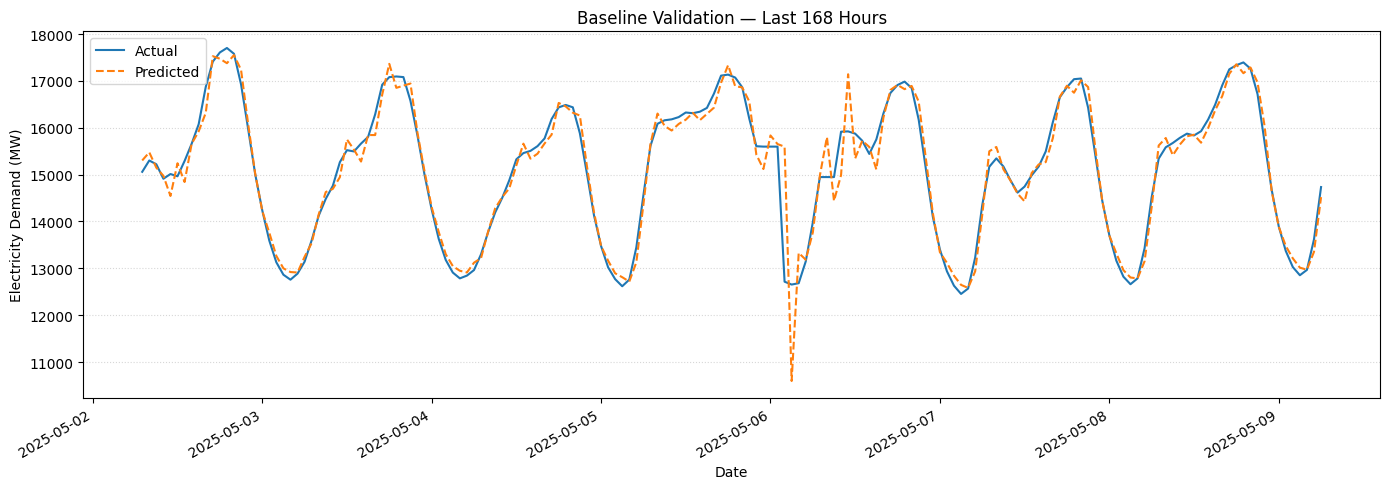


Experiment summary:
Experiment                               Val MAE    Epoch
----------------------------------------------------------
Baseline LSTM                             0.0759       26

MAE is in scaled units; epoch selected by minimum validation MSE.


In [8]:
def evaluate_forecast(
    model, X, y,
    *,
    title="Validation",
    target_scaler=None,
    datetime_index=None,
    plot_last_hours=24*7
):
    """Evaluate direct forecasts using MAE; average overlaps for plotting."""

    y_pred = np.asarray(model.predict(X, verbose=0))
    y_true = np.asarray(y)

    if y_pred.ndim == 1:
        y_pred = y_pred[:, None]
    if y_true.ndim == 1:
        y_true = y_true[:, None]

    if y_pred.shape != y_true.shape:
        raise ValueError(
            f"Shape mismatch: predictions {y_pred.shape}, "
            f"targets {y_true.shape}"
        )

    H = y_pred.shape[1]

    # Convert from scaled values to original units
    def convert_units(arr):
        if target_scaler is None:
            return arr
        original_shape = arr.shape
        converted = target_scaler.inverse_transform(
            arr.reshape(-1, 1)
        )
        return converted.reshape(original_shape)

    y_pred_u = convert_units(y_pred)
    y_true_u = convert_units(y_true)

    units = "MW" if target_scaler is not None else "scaled"

    # Overall MAE, computed before averaging overlapping predictions
    errors = y_pred_u - y_true_u
    mae = float(np.mean(np.abs(errors)))

    print(f"{title} MAE: {mae:.2f} {units}")

    # MAE at each forecast horizon
    mae_by_step = np.mean(np.abs(errors), axis=0)

    if H > 1:
        print("\nMAE by forecast step:")
        for h in range(H):
            print(f"  Hour {h+1:2d}: MAE = {mae_by_step[h]:.2f} {units}")

    # Average overlapping forecasts to produce one continuous timeline
    def stitch_predictions(arr):
        n, horizon = arr.shape
        total = n + horizon - 1

        sums = np.zeros(total)
        counts = np.zeros(total)

        for i in range(n):
            sums[i:i+horizon] += arr[i]
            counts[i:i+horizon] += 1

        return sums / counts

    true_timeline = stitch_predictions(y_true_u)
    pred_timeline = stitch_predictions(y_pred_u)

    N = min(plot_last_hours, len(true_timeline))

    if datetime_index is not None:
        if len(datetime_index) != len(true_timeline):
            raise ValueError("Datetime index length does not match forecast.")
        x_axis = datetime_index[-N:]
    else:
        x_axis = np.arange(len(true_timeline) - N, len(true_timeline))

    # Plot
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        x_axis,
        true_timeline[-N:],
        label="Actual"
    )

    ax.plot(
        x_axis,
        pred_timeline[-N:],
        linestyle="--",
        label="Predicted"
    )

    ax.set_title(f"{title} — Last {N} Hours")
    ax.set_xlabel("Date" if datetime_index is not None else "Hour")
    ax.set_ylabel(f"Electricity Demand ({units})")
    ax.grid(True, axis="y", linestyle=":", alpha=0.5)
    ax.legend()

    if datetime_index is not None:
        fig.autofmt_xdate()

    plt.tight_layout()
    plt.show()

    return {
        "mae": mae,
        "mae_by_step": mae_by_step
    }


# Evaluate baseline on validation data
baseline_validation = evaluate_forecast(
    baseline_model,
    baseline_X_val,
    baseline_y_val,
    title="Baseline Validation",
    target_scaler=scaler,
    datetime_index=val.index,
    plot_last_hours=24*7
)

print("\nExperiment summary:")
print_results()

## Problem One — Exploring Lookback and Horizon

In this problem, we investigate how the **amount of historical context** (`lookback`) and the **number of hours predicted** (`horizon`) affect forecasting performance. Keep the baseline LSTM architecture and training settings unchanged so that only these two parameters vary.

Run these four configurations:

| Experiment | Lookback | Horizon | What changes? |
|---|---:|---:|---|
| Baseline (already trained) | 168 hours (7 days) | 1 hour | Reference |
| A | 24 hours (1 day) | 1 hour | Shorter lookback |
| B | 336 hours (14 days) | 1 hour | Longer lookback |
| C | 168 hours (7 days) | 24 hours | Longer forecasting horizon |

For each of **A, B, and C**:

1. Use `build_datasets(lookback, horizon)` to create the appropriate training and validation windows. Do **not** edit the setup cells or overwrite the baseline model.
2. Create a **new** model with `make_baseline_model(lookback, horizon)`. Set the random seed before creating each model so the experiments are as comparable as possible.
3. Train with `train_and_validate(...)`, supplying the corresponding training and validation arrays explicitly. The function chooses the epoch with minimum validation MSE (`val_loss`) and records the **validation MAE at that epoch**.
4. Compare the results with the baseline using `print_results()`. The reported MAEs are in **scaled units**.

**Comparison:** Baseline, A, and B are all one-hour-ahead forecasts and can be compared directly to investigate lookback length. Experiment C predicts **24 steps at once**, so its MAE averages over different lead times and is not strictly the same task as one-hour-ahead prediction. We will explore the implications of multi-step forecasting later.

**Do not evaluate on the test set.** We reserve it for the final model evaluation.



Problem 1A: Lookback 24, Horizon 1



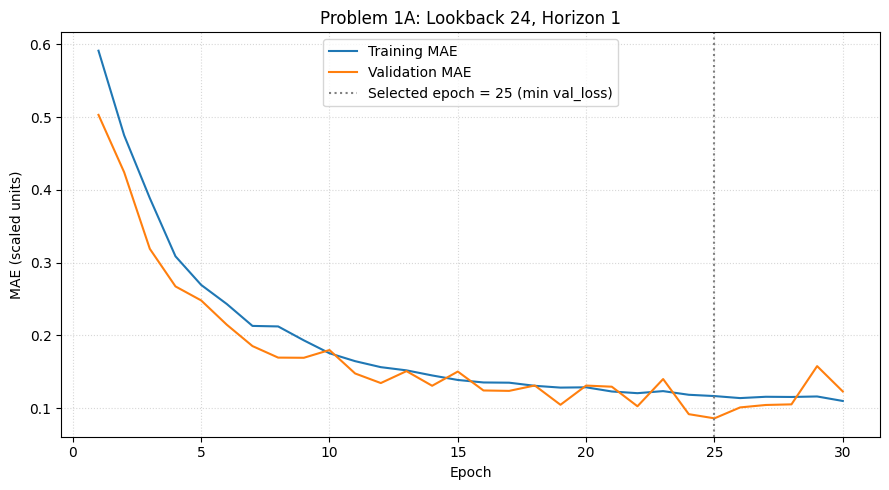

Selected epoch: 25 (minimum validation MSE)
Training MAE:   0.1166
Validation MAE: 0.0860
Training time: 00:00:18
Experiment                               Val MAE    Epoch
----------------------------------------------------------
Baseline LSTM                             0.0759       26
Problem 1A: Lookback 24, Horizon 1        0.0860       25

MAE is in scaled units; epoch selected by minimum validation MSE.


In [9]:
# Your code here; add as many cells as you wish

# Experiment A: 24-hour lookback, 1-hour horizon
X_train_a, y_train_a, X_val_a, y_val_a, _, _ = build_datasets(
    lookback=24, horizon=1
)

tf.keras.utils.set_random_seed(random_seed)
model_1a = make_baseline_model(lookback=24, horizon=1)

info_1a = train_and_validate(
    model_1a,
    X_train=X_train_a,
    y_train=y_train_a,
    X_val=X_val_a,
    y_val=y_val_a,
    title="Problem 1A: Lookback 24, Horizon 1"
)

print_results()


Problem 1B: Lookback 336, Horizon 1



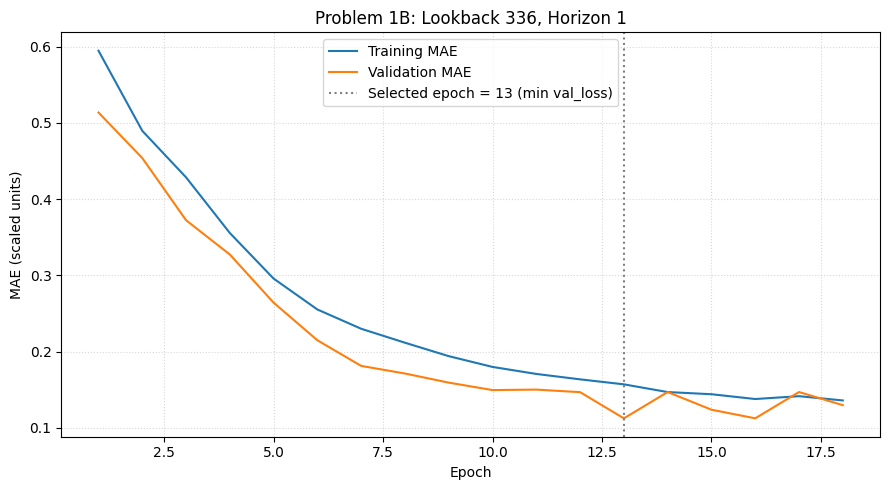

Selected epoch: 13 (minimum validation MSE)
Training MAE:   0.1569
Validation MAE: 0.1123
Training time: 00:00:16
Experiment                               Val MAE    Epoch
----------------------------------------------------------
Baseline LSTM                             0.0759       26
Problem 1A: Lookback 24, Horizon 1        0.0860       25
Problem 1B: Lookback 336, Horizon 1       0.1123       13

MAE is in scaled units; epoch selected by minimum validation MSE.


In [12]:
# Experiment B: 336-hour lookback, 1-hour horizon
X_train_b, y_train_b, X_val_b, y_val_b, _, _ = build_datasets(
    lookback=336, horizon=1
)

tf.keras.utils.set_random_seed(random_seed)
model_1b = make_baseline_model(lookback=336, horizon=1)

info_1b = train_and_validate(
    model_1b,
    X_train=X_train_b,
    y_train=y_train_b,
    X_val=X_val_b,
    y_val=y_val_b,
    title="Problem 1B: Lookback 336, Horizon 1"
)

print_results()


Problem 1C: Lookback 168, Horizon 24



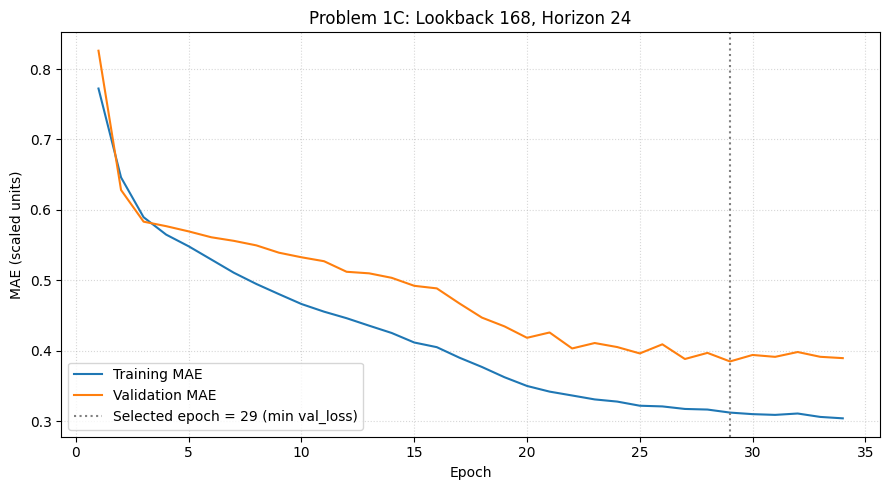

Selected epoch: 29 (minimum validation MSE)
Training MAE:   0.3122
Validation MAE: 0.3848
Training time: 00:00:18
Experiment                               Val MAE    Epoch
----------------------------------------------------------
Baseline LSTM                             0.0759       26
Problem 1A: Lookback 24, Horizon 1        0.0860       25
Problem 1B: Lookback 336, Horizon 1       0.1123       13
Problem 1C: Lookback 168, Horizon 24       0.3848       29

MAE is in scaled units; epoch selected by minimum validation MSE.


In [15]:
# Experiment C: 168-hour lookback, 24-hour horizon
X_train_c, y_train_c, X_val_c, y_val_c, _, _ = build_datasets(
    lookback=168, horizon=24
)

tf.keras.utils.set_random_seed(random_seed)
model_1c = make_baseline_model(lookback=168, horizon=24)

info_1c = train_and_validate(
    model_1c,
    X_train=X_train_c,
    y_train=y_train_c,
    X_val=X_val_c,
    y_val=y_val_c,
    title="Problem 1C: Lookback 168, Horizon 24"
)

print_results()

### Graded Questions

Enter the **scaled validation MAE at the epoch of minimum validation MSE** for each experiment. Use the values from the training summaries above. Do not enter MAE in MW.


In [10]:
# Set a1a to the scaled validation MAE at the epoch of minimum validation loss (MSE) for Experiment A: lookback 24, horizon 1

a1a = info_1a["val_mae_at_min_valloss"]            # Replace 0.0 with your answer

In [11]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a1a = {a1a:.4f}')

a1a = 0.0860


In [13]:
# Set a1b to the scaled validation MAE at the epoch of minimum validation loss (MSE) for Experiment B: lookback 336, horizon 1

a1b = info_1b["val_mae_at_min_valloss"]            # Replace 0.0 with your answer

In [14]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a1b = {a1b:.4f}')

a1b = 0.1123


In [16]:
# Set a1c to the scaled validation MAE at the epoch of minimum validation loss (MSE) for Experiment C: lookback 168, horizon 24

a1c =info_1c["val_mae_at_min_valloss"]            # Replace 0.0 with your answer

In [17]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a1c = {a1c:.4f}')

a1c = 0.3848


## Problem Two — Exploring LSTM Architectures

In this problem, investigate how the **architecture** of an LSTM model affects forecasting performance. Keep the forecasting task fixed at **lookback = 168 hours (7 days)** and **horizon = 1 hour** for all three experiments. This lets you compare architectures fairly against the original baseline.

Use the same training procedure as the baseline: Adam, MSE training loss, early stopping based on `val_loss` (validation MSE), and **scaled validation MAE at the selected epoch** for reporting.

Train the following models, keeping `Dropout(0.2)` and a final linear `Dense(1)` output:

| Experiment | Architecture | Change from baseline |
|---|---|---|
| **A** | `LSTM(32) → Dropout(0.2) → Dense(32, relu) → Dense(16, relu) → Dense(1)` | Add a second Dense hidden layer |
| **B** | `LSTM(32, return_sequences=True) → LSTM(32) → Dropout(0.2) → Dense(16, relu) → Dense(1)` | Stack two LSTM layers |
| **C** | `Bidirectional(LSTM(32)) → Dropout(0.2) → Dense(16, relu) → Dense(1)` | Process the historical input window in both directions |

Use He initialization for the hidden Dense layers as in the baseline. **Reset the random seed immediately before building each model.** Do not use the test set to compare models.

A bidirectional LSTM does **not** introduce future-target leakage here: both directions operate only on the historical lookback window. After training, use `print_results()` to compare experiments A–C with the baseline.


Problem 2A: Deeper Dense Head



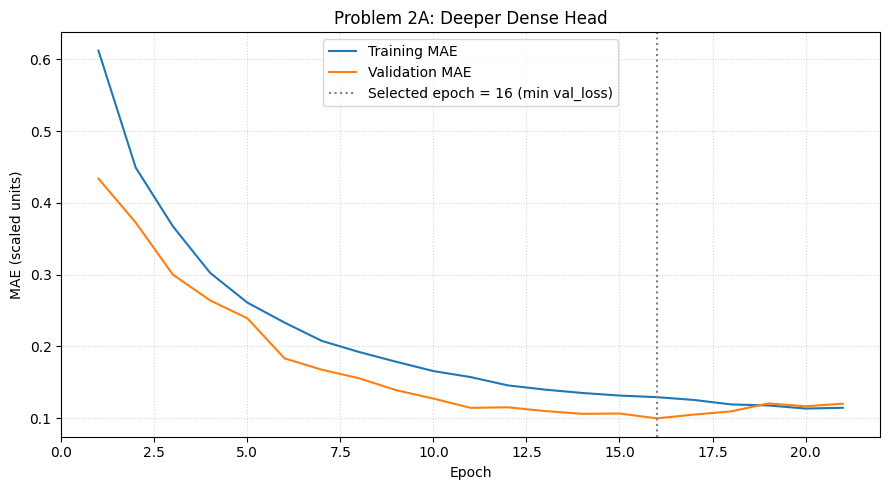

Selected epoch: 16 (minimum validation MSE)
Training MAE:   0.1294
Validation MAE: 0.0999
Training time: 00:00:11
Experiment                               Val MAE    Epoch
----------------------------------------------------------
Baseline LSTM                             0.0759       26
Problem 1A: Lookback 24, Horizon 1        0.0860       25
Problem 2A: Deeper Dense Head             0.0999       16
Problem 1B: Lookback 336, Horizon 1       0.1123       13
Problem 1C: Lookback 168, Horizon 24       0.3848       29

MAE is in scaled units; epoch selected by minimum validation MSE.


In [18]:
# Your code here; add as many cells as you like
# Same forecasting task as the baseline
X_train_2, y_train_2, X_val_2, y_val_2, _, _ = build_datasets(
    lookback=168, horizon=1
)

tf.keras.utils.set_random_seed(random_seed)

model_2a = Sequential([
    Input(shape=(168, 1)),
    LSTM(32),
    Dropout(0.2),
    Dense(
        32, activation="relu",
        kernel_initializer=keras.initializers.HeNormal(seed=random_seed)
    ),
    Dense(
        16, activation="relu",
        kernel_initializer=keras.initializers.HeNormal(seed=random_seed)
    ),
    Dense(1)
])

info_2a = train_and_validate(
    model_2a,
    X_train=X_train_2,
    y_train=y_train_2,
    X_val=X_val_2,
    y_val=y_val_2,
    title="Problem 2A: Deeper Dense Head"
)

print_results()



Problem 2B: Stacked LSTMs



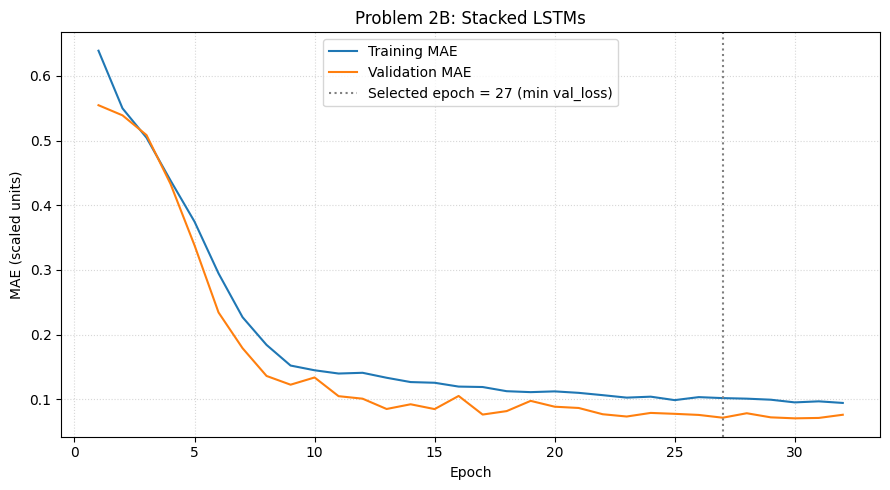

Selected epoch: 27 (minimum validation MSE)
Training MAE:   0.1018
Validation MAE: 0.0715
Training time: 00:00:24
Experiment                               Val MAE    Epoch
----------------------------------------------------------
Problem 2B: Stacked LSTMs                 0.0715       27
Baseline LSTM                             0.0759       26
Problem 1A: Lookback 24, Horizon 1        0.0860       25
Problem 2A: Deeper Dense Head             0.0999       16
Problem 1B: Lookback 336, Horizon 1       0.1123       13
Problem 1C: Lookback 168, Horizon 24       0.3848       29

MAE is in scaled units; epoch selected by minimum validation MSE.


In [21]:
# Experiment 2B: stacked LSTM layers
tf.keras.utils.set_random_seed(random_seed)

model_2b = Sequential([
    Input(shape=(168, 1)),
    LSTM(32, return_sequences=True),
    LSTM(32),
    Dropout(0.2),
    Dense(
        16, activation="relu",
        kernel_initializer=keras.initializers.HeNormal(seed=random_seed)
    ),
    Dense(1)
])

info_2b = train_and_validate(
    model_2b,
    X_train=X_train_2,
    y_train=y_train_2,
    X_val=X_val_2,
    y_val=y_val_2,
    title="Problem 2B: Stacked LSTMs"
)

print_results()


Problem 2C: Bidirectional LSTM



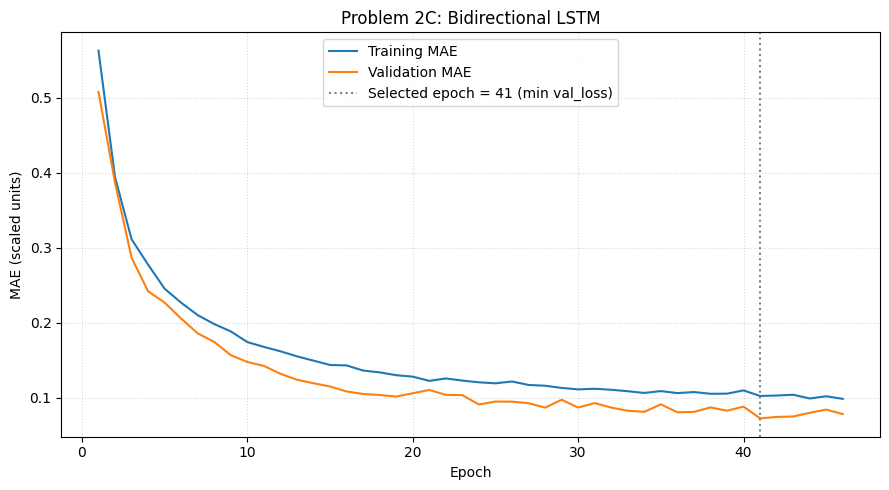

Selected epoch: 41 (minimum validation MSE)
Training MAE:   0.1027
Validation MAE: 0.0729
Training time: 00:00:31
Experiment                               Val MAE    Epoch
----------------------------------------------------------
Problem 2B: Stacked LSTMs                 0.0715       27
Problem 2C: Bidirectional LSTM            0.0729       41
Baseline LSTM                             0.0759       26
Problem 1A: Lookback 24, Horizon 1        0.0860       25
Problem 2A: Deeper Dense Head             0.0999       16
Problem 1B: Lookback 336, Horizon 1       0.1123       13
Problem 1C: Lookback 168, Horizon 24       0.3848       29

MAE is in scaled units; epoch selected by minimum validation MSE.


In [23]:
# Experiment 2C: bidirectional LSTM
tf.keras.utils.set_random_seed(random_seed)

model_2c = Sequential([
    Input(shape=(168, 1)),
    Bidirectional(LSTM(32)),
    Dropout(0.2),
    Dense(
        16, activation="relu",
        kernel_initializer=keras.initializers.HeNormal(seed=random_seed)
    ),
    Dense(1)
])

info_2c = train_and_validate(
    model_2c,
    X_train=X_train_2,
    y_train=y_train_2,
    X_val=X_val_2,
    y_val=y_val_2,
    title="Problem 2C: Bidirectional LSTM"
)

print_results()

### Graded Questions

Enter the **scaled validation MAE at the epoch of minimum validation loss (MSE)** for each experiment.  The cells below are deliberately separate so each can be graded independently.

In [19]:
# Set a2a to scaled validation MAE at min val_loss for Experiment A (deeper Dense head).

a2a = info_2a["val_mae_at_min_valloss"]  # Replace 0.0 with your answer

In [20]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2a = {a2a:.4f}')

a2a = 0.0999


In [22]:
# Set a2b to scaled validation MAE at min val_loss for Experiment B (stacked LSTMs).

a2b = info_2b["val_mae_at_min_valloss"]  # Replace 0.0 with your answer

In [24]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2b = {a2b:.4f}')

a2b = 0.0715


In [25]:
# Set a2c to scaled validation MAE at min val_loss for Experiment C (bidirectional LSTM).

a2c =  info_2b["val_mae_at_min_valloss"]   # Replace 0.0 with your answer

In [26]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2c = {a2c:.4f}')

a2c = 0.0715


## Problem Three — Direct vs. Autoregressive Forecasting

In **direct forecasting** (Problem 1, Experiment C), an LSTM predicts all 24 future hourly values in one forward pass. In **autoregressive (recursive) forecasting**, a one-step LSTM predicts the next hour, removes the oldest observation, appends its prediction to maintain a fixed-length input window, and repeats the process for 24 hours. Errors can accumulate because later predictions depend on earlier predicted values. We *jumpstart* the process with a lookback window, just as with direct forecasting.


The LSTM is trained using actual historical observations to predict one hour ahead. During autoregressive forecasting, its weights remain fixed; only the input window changes as predicted values replace actual observations.

> Use a **168-hour lookback** for both methods. Compare the previously trained **one-step baseline LSTM** (used recursively) with a **direct 24-hour LSTM** having the same architecture as Problem 1, Experiment C.

Your tasks:

1. Write a function that takes a batch of 168-hour input windows and returns **24 recursive predictions** per window. At each iteration, remove the oldest observation and append the model's prediction. Do not substitute actual future values as input during the rollout.
2. Generate recursive forecasts for the validation set, with shape `(n_windows, 24)`.
3. Obtain direct 24-hour predictions over **exactly the same validation windows and target values**. You may reuse the direct 24-hour model from Problem 1, Experiment C, if you saved it. Otherwise, train a new model using the same architecture and training configuration.
4. Compute the **scaled MAE at each of the 24 forecast lead times** for both approaches. Plot MAE versus forecast hour, with one curve for direct forecasting and one for autoregressive forecasting.
5. Compute the overall scaled MAE for the autoregressive method, averaging errors across all windows and all 24 horizons. Use your results to answer the numerical graded questions.

**Evaluation:** Use the validation set, not the held-out test set. The direct and recursive methods must use identical forecast origins and targets. No additional discussion answer is required.


Autoregressive hour 1 MAE:  0.0764
Autoregressive hour 24 MAE: 0.5196
Autoregressive overall MAE: 0.4871
Direct overall MAE:         0.3848


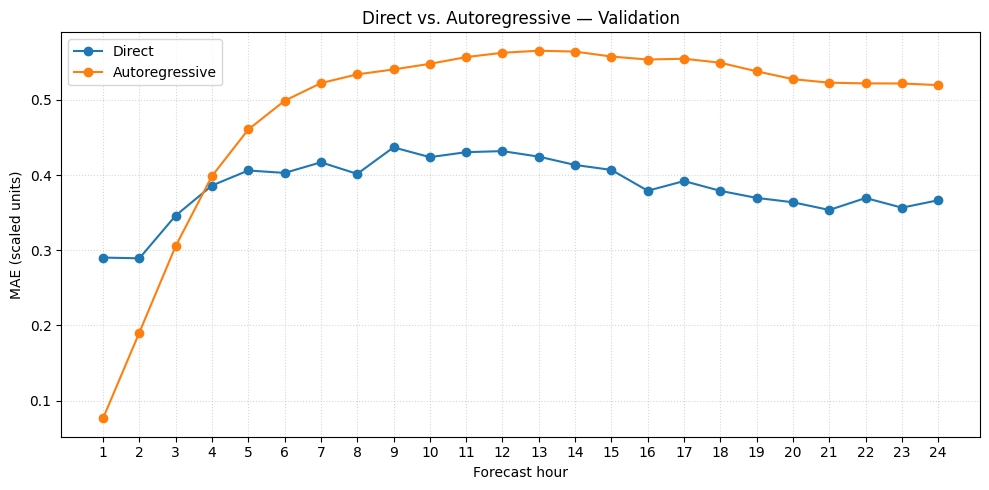

In [27]:
# Your code here; add as many cells as you like
def recursive_forecast(model, X, horizon=24):
    """Predict recursively without using actual future observations."""
    window = np.array(X, dtype=np.float32, copy=True)
    predictions = []

    for step in range(horizon):
        next_pred = model.predict(window, verbose=0).reshape(-1)
        predictions.append(next_pred)

        # Remove oldest hour and append predicted hour
        window = np.concatenate(
            [window[:, 1:, :], next_pred[:, None, None]],
            axis=1
        )

    return np.stack(predictions, axis=1)


# Both methods use identical input windows and 24-hour targets
X_val_24 = X_val_c
y_val_24 = y_val_c

recursive_val_pred = recursive_forecast(
    baseline_model, X_val_24, horizon=24
)

direct_val_pred = model_1c.predict(X_val_24, verbose=0)

assert recursive_val_pred.shape == direct_val_pred.shape == y_val_24.shape

# Scaled MAE for each forecast hour
recursive_mae_by_hour = np.mean(
    np.abs(recursive_val_pred - y_val_24), axis=0
)
direct_mae_by_hour = np.mean(
    np.abs(direct_val_pred - y_val_24), axis=0
)

# Overall scaled MAE
recursive_val_mae = float(
    np.mean(np.abs(recursive_val_pred - y_val_24))
)
direct_val_mae = float(
    np.mean(np.abs(direct_val_pred - y_val_24))
)

print(f"Autoregressive hour 1 MAE:  {recursive_mae_by_hour[0]:.4f}")
print(f"Autoregressive hour 24 MAE: {recursive_mae_by_hour[-1]:.4f}")
print(f"Autoregressive overall MAE: {recursive_val_mae:.4f}")
print(f"Direct overall MAE:         {direct_val_mae:.4f}")

hours = np.arange(1, 25)

plt.figure(figsize=(10, 5))
plt.plot(hours, direct_mae_by_hour, marker="o", label="Direct")
plt.plot(hours, recursive_mae_by_hour, marker="o", label="Autoregressive")
plt.xlabel("Forecast hour")
plt.ylabel("MAE (scaled units)")
plt.title("Direct vs. Autoregressive — Validation")
plt.xticks(hours)
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Graded Questions

Report **scaled validation MAE** from the autoregressive forecasts. Use the *same 24-hour validation targets* used in the direct comparison. Keep each answer in its own cell; do not change the graded-print cells.


In [28]:
# Set a3a to the autoregressive validation MAE for forecast hour 1.

a3a = float(recursive_mae_by_hour[0])  # Replace 0.0 with your answer


In [29]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a3a = {a3a:.4f}')


a3a = 0.0764


In [30]:
# Set a3b to the autoregressive validation MAE for forecast hour 24.

a3b = float(recursive_mae_by_hour[-1]) # Replace 0.0 with your answer


In [31]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a3b = {a3b:.4f}')


a3b = 0.5196


In [32]:
# Set a3c to the overall autoregressive validation MAE across all 24 forecast hours.

a3c = recursive_val_mae  # Replace 0.0 with your answer


In [33]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a3c = {a3c:.4f}')


a3c = 0.4871


## Problem Four — Final Evaluation on the Test Set

Throughout this homework, we have used the **training set** to train our models and the **validation set** to select the best configurations and compare forecasting strategies. We have kept the **test set** separate to obtain an unbiased estimate of how our selected model performs on unseen data.

In Problem 3, we compared direct and autoregressive 24-hour forecasting. We will now select the approach with the lower overall validation MAE and evaluate it on the held-out test set.

**Your tasks:**

1. Identify the 24-hour forecasting model with the lowest overall validation MAE from Problem 3. Use the already-trained model; do not retrain it or modify its hyperparameters.
2. Use `build_datasets(lookback=168, horizon=24)` to obtain the test input windows and targets.
3. Generate predictions on the test set and calculate the **overall test MAE**, averaging across all forecast windows and all 24 forecast hours.
4. Report the test MAE in both **scaled units** and the original units (**MW**).
5. Plot the actual and predicted electricity demand over the **last seven days of the test period**, averaging overlapping predictions when necessary to produce a continuous forecast.

**Important:** Evaluate the selected model only once on the test set. Do not use the test results to change the model architecture, hyperparameters, or forecasting strategy.

This final evaluation provides an estimate of how well the model selected using validation data generalizes to previously unseen observations.

Selected method: Direct
Test MAE (scaled): 0.4106
Test MAE (MW): 953.61


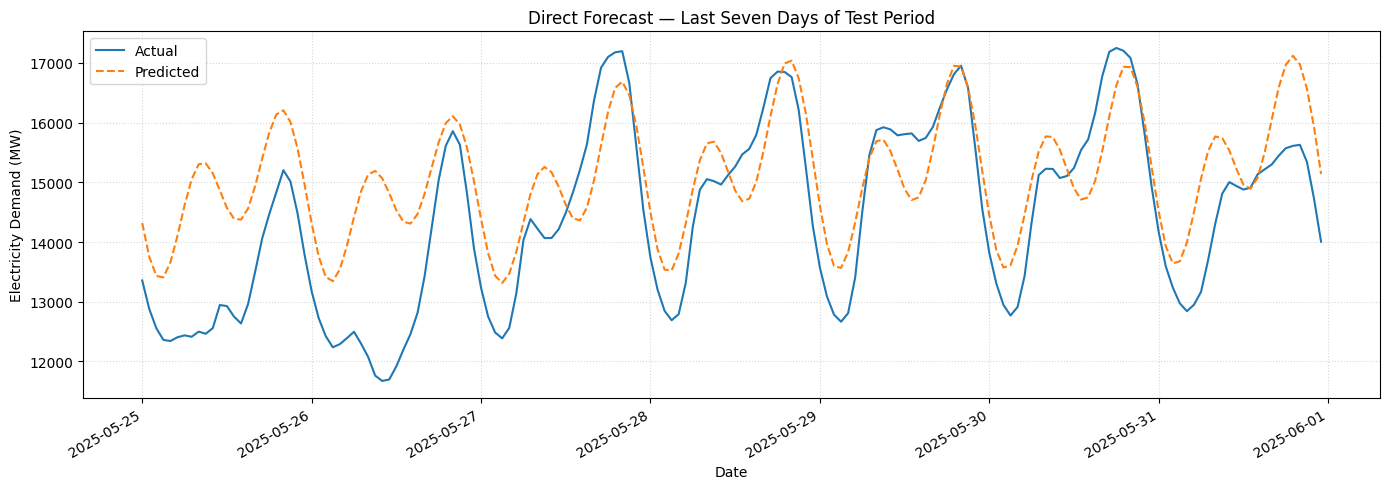

In [34]:
# Your code here; add as many cells as you wish

# Select the method using validation results only
selected_method = 1 if direct_val_mae <= recursive_val_mae else 2

# Obtain test windows for the 24-hour forecasting task
_, _, _, _, X_test_24, y_test_24 = build_datasets(
    lookback=168, horizon=24
)

# Generate test predictions using only the selected method
if selected_method == 1:
    test_pred = model_1c.predict(X_test_24, verbose=0)
    method_name = "Direct"
else:
    test_pred = recursive_forecast(
        baseline_model, X_test_24, horizon=24
    )
    method_name = "Autoregressive"

# Overall MAE before averaging overlapping predictions
test_mae_scaled = float(np.mean(np.abs(test_pred - y_test_24)))
test_mae_mw = test_mae_scaled * float(scaler.scale_[0])

print(f"Selected method: {method_name}")
print(f"Test MAE (scaled): {test_mae_scaled:.4f}")
print(f"Test MAE (MW): {test_mae_mw:.2f}")

# Convert predictions and targets to MW
pred_mw = scaler.inverse_transform(
    test_pred.reshape(-1, 1)
).reshape(test_pred.shape)

true_mw = scaler.inverse_transform(
    y_test_24.reshape(-1, 1)
).reshape(y_test_24.shape)


def average_overlaps(values):
    n_windows, horizon = values.shape
    sums = np.zeros(n_windows + horizon - 1)
    counts = np.zeros_like(sums)

    for i in range(n_windows):
        sums[i:i + horizon] += values[i]
        counts[i:i + horizon] += 1

    return sums / counts


pred_timeline = average_overlaps(pred_mw)
true_timeline = average_overlaps(true_mw)

# Plot the final seven days
plt.figure(figsize=(14, 5))
plt.plot(test.index[-168:], true_timeline[-168:], label="Actual")
plt.plot(
    test.index[-168:], pred_timeline[-168:],
    linestyle="--", label="Predicted"
)
plt.title(f"{method_name} Forecast — Last Seven Days of Test Period")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")
plt.grid(True, linestyle=":", alpha=0.5)
plt.legend()
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.show()

### Graded Questions


In [35]:
# Set a4a to the forecasting method selected for final test evaluation.
# 1 = Direct 24-hour forecasting
# 2 = Autoregressive 24-hour forecasting

a4a = selected_method    # Replace 0 with your answer

In [36]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a4a = {a4a}')


a4a = 1


In [37]:
# Set a4b to the overall test MAE of your chosen model in scaled units,
# averaged across all forecast windows and all 24 hours.

a4b = test_mae_scaled    # Replace 0.0 with your answer


In [38]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a4b = {a4b:.4f}')


a4b = 0.4106


In [39]:
# Set a4c to the overall test MAE of your chosen model in megawatts (MW),
# averaged across all forecast windows and all 24 hours.

a4c = test_mae_mw    # Replace 0.0 with your answer


In [40]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a4c = {a4c:.4f}')


a4c = 953.6092
